In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, Point
import numpy as np
import matplotlib.pyplot as plt
import time
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches


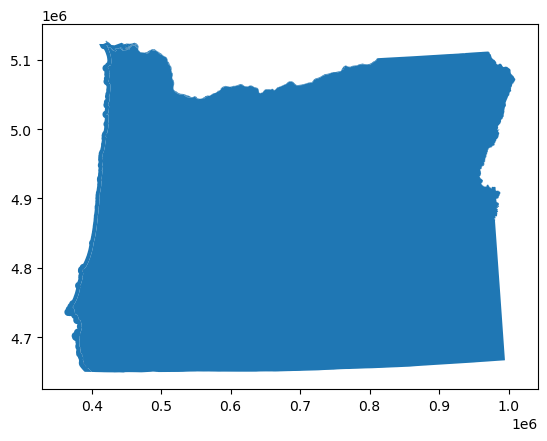

In [2]:
#oregon outline
oregon = gpd.read_file('C:/Users/sarah/Desktop/ORKA/GISResources/OregonState_Shapefile_HigherRes/Oregon_State_Boundary.shp')
or_trans = oregon.to_crs("EPSG:26910")
or_trans.plot()
or_sea = or_trans.loc[or_trans.FEATURE == 0].reset_index()

In [3]:
#get sites 
temp = pd.read_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Data/MasterSites_WithTempMetrics_20132024.csv')
sites = temp.iloc[1:15,[1,6,7]]
sites_gdf = gpd.GeoDataFrame(
    sites, geometry=gpd.points_from_xy(sites.SiteLongitude, sites.SiteLatitude), crs="EPSG:4326"
)
sites_trans = sites_gdf.to_crs("EPSG:26910")


In [4]:
#transect locations
d = pd.read_csv("C:/Users/sarah/Documents/GitHub/PermittingGrantReportingCodeFigures/MasterTransects_UpdatedNov2025.csv")
d["Date"] = pd.to_datetime(d.Date, format='%Y-%m-%d')
d23 = d.loc[(d["Date"].dt.date >= pd.to_datetime("2023-01-01").date()) & (d.Date.dt.date <= pd.to_datetime("2023-12-31").date())].reset_index()
site_dict =  { "Pacific City":[], "Cape Foulweather":[], "Otter Rock":[], "Gregory Point":[], "Simpson Reef":[],
             "Drake Point":[], "Blanco Reef":[], "Orford Reef":[], "Port Orford Heads":[], "Redfish Rocks":[], "Humbug":[],
             "Rogue Reef":[], "Harris Beach":[], "Chetco Point":[]}
dsub = d23.loc[(d23.Site == "Pacific City South") | (d23.Site == "Pacific City North"),  ]
subsites = dsub.iloc[:,[18,17]].drop_duplicates()
for site in list(site_dict.keys()):
    if (site == "Pacific City"):
        print("do nothing!")
    elif (site == "Harris Beach"):
        print(site, "second loop ")
        dsub = d23.loc[d23.Site == "Boardman Corridor"] 
        thing = dsub.iloc[:,[18,17]].drop_duplicates()
        subsites = pd.concat([subsites,thing]).reset_index(drop = True)
    else:
        print(site, "third loop ")
        dsub = d23.loc[d23.Site == site] 
        thing = dsub.iloc[:,[18,17]].drop_duplicates()
        subsites = pd.concat([subsites,thing], ignore_index = True).reset_index(drop = True)
subsites
sub_gdf = gpd.GeoDataFrame(
    subsites, geometry=gpd.points_from_xy(subsites.SurveyLongitude, subsites.SurveyLatitude), crs="EPSG:4326"
)
sub_trans = sub_gdf.to_crs("EPSG:26910")
sub_trans

do nothing!
Cape Foulweather third loop 
Otter Rock third loop 
Gregory Point third loop 
Simpson Reef third loop 
Drake Point third loop 
Blanco Reef third loop 
Orford Reef third loop 
Port Orford Heads third loop 
Redfish Rocks third loop 
Humbug third loop 
Rogue Reef third loop 
Harris Beach second loop 
Chetco Point third loop 


C:\Users\sarah\AppData\Local\Temp\ipykernel_26152\791685543.py:2: DtypeWarning: Columns (11,22) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv("C:/Users/sarah/Documents/GitHub/PermittingGrantReportingCodeFigures/MasterTransects_UpdatedNov2025.csv")


,SurveyLongitude,SurveyLatitude,geometry
0,-123.984928,45.212367,POINT (422659.764 5007014.997)
1,-123.985372,45.212570,POINT (422625.175 5007037.974)
2,-124.076020,44.792410,POINT (414886.758 4960454.419)
3,-124.076040,44.792350,POINT (414885.088 4960447.775)
4,-124.076770,44.795280,POINT (414831.658 4960774.016)
...,...,...,...
81,-124.470870,42.447910,POINT (379042.434 4700556.384)
82,-124.481770,42.447650,POINT (378145.552 4700543.1)
83,-124.308265,42.063682,POINT (391759.595 4657674.452)
84,-124.287373,42.042975,POINT (393453.536 4655349.09)


In [5]:
#Ignore this. Just use Kelp Watch since you're using Kelp Watch for the models as well. One less dataset to discuss in the 
#methods section
#ODFW kelp for everything but pacific city
#kelp10 = gpd.read_file('C:/Users/sarah/Desktop/ORKA/GISResources/ODFWKelpPolygons/ODFWKelpSurvey_2010_Updated/ODFW_kelp2010_rev2.shp')
#kelp10["Area_m2"] = kelp10.geometry.area
#kelpcombo = gpd.read_file('C:/Users/sarah/Desktop/ORKA/GISResources/ODFWKelpPolygons/kelp_canopy_90s_2010.shp')


In [5]:
#kelpwatch kelp for pacific city
kelpwatch = gpd.read_file('C:/Users/sarah/Desktop/ORKA/GISResources/KelpShapefile_OR/KelpCanopy_Hamilton2020data.shp')
kw_trans = kelpwatch.to_crs("EPSG:26910")


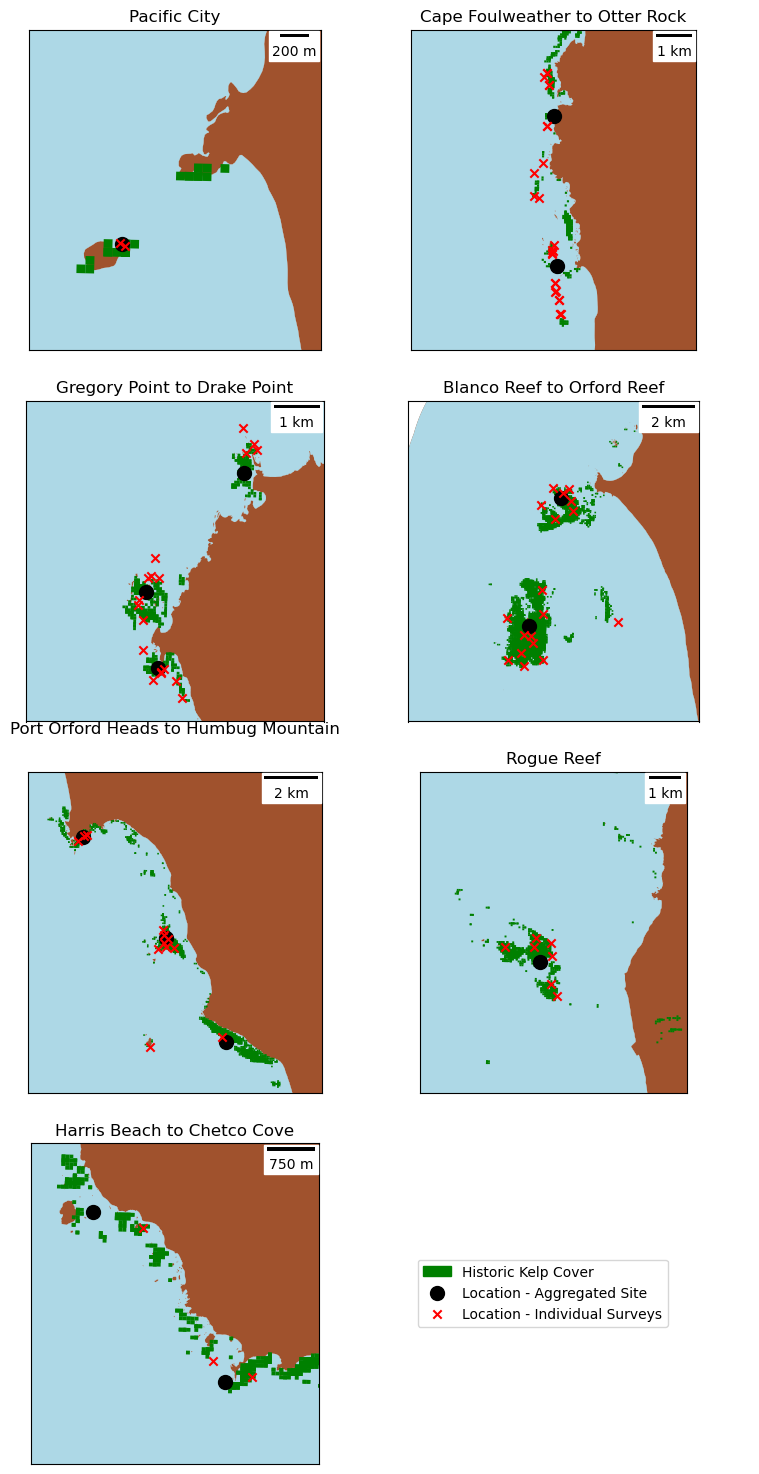

In [6]:
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6), (ax7, ax8)) = plt.subplots(4,2, figsize = (8,15))
#pacific
or_trans.plot(ax = ax1, color = "sienna")
or_sea.plot(ax = ax1, color = "lightblue")
kw_trans.plot(ax = ax1, color = "green")
p1 = ax1.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
ax1.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax1.add_artist(ScaleBar(1))
ax1.set_xlim(422000, 424000)
ax1.set_ylim(5006300, 5008500)
ax1.set_title("Pacific City")
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)
#Foulweather
or_trans.plot(ax = ax2, color = "sienna")
or_sea.plot(ax = ax2, color = "lightblue")
kw_trans.plot(ax = ax2, color = "green")
p2 = ax2.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
ax2.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax2.add_artist(ScaleBar(1))
ax2.set_xlim(411000, 419000)
ax2.set_ylim(4953000, 4962000)
ax2.set_title("Cape Foulweather to Otter Rock")
ax2.get_xaxis().set_visible(False)
ax2.get_yaxis().set_visible(False)
#Arago
or_trans.plot(ax = ax3, color = "sienna")
or_sea.plot(ax = ax3, color = "lightblue")
kw_trans.plot(ax = ax3, color = "green")
ax3.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
ax3.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax3.add_artist(ScaleBar(1))
ax3.set_xlim(383500, 390000)
ax3.set_ylim(4794000, 4801000)
ax3.set_title("Gregory Point to Drake Point")
ax3.get_xaxis().set_visible(False)
ax3.get_yaxis().set_visible(False)
#Orford
or_trans.plot(ax = ax4, color = "sienna")
or_sea.plot(ax = ax4, color = "lightblue")
kw_trans.plot(ax = ax4, color = "green")
ax4.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
ax4.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax4.add_artist(ScaleBar(1))
ax4.set_xlim(365000, 375900)
ax4.set_ylim(4735000, 4747000) 
ax4.set_title("Blanco Reef to Orford Reef")
ax4.get_xaxis().set_visible(False)
ax4.get_yaxis().set_visible(False)
#Port Orford
or_trans.plot(ax = ax5, color = "sienna")
or_sea.plot(ax = ax5, color = "lightblue")
kw_trans.plot(ax = ax5, color = "green")
ax5.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y,s = 100, color = "black")
ax5.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax5.add_artist(ScaleBar(1))
ax5.set_xlim(374500, 385500)
ax5.set_ylim(4723000, 4735000) 
ax5.set_title("Port Orford Heads to Humbug Mountain")
ax5.get_xaxis().set_visible(False)
ax5.get_yaxis().set_visible(False)
#Rogue
or_trans.plot(ax = ax6, color = "sienna")
or_sea.plot(ax = ax6, color = "lightblue")
kw_trans.plot(ax = ax6, color = "green")
ax6.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
ax6.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax6.add_artist(ScaleBar(1))
ax6.set_xlim(375500,383800)
ax6.set_ylim(4696000, 4706000) 
ax6.set_title("Rogue Reef")
ax6.get_xaxis().set_visible(False)
ax6.get_yaxis().set_visible(False)
#Brookings
or_trans.plot(ax = ax7, color = "sienna")
or_sea.plot(ax = ax7, color = "lightblue")
thing1 = kw_trans.plot(ax = ax7, color = "green", legend = True, label = "Historic Kelp")
thing2 = ax7.scatter(x = sites_trans.geometry.x, y = sites_trans.geometry.y, s = 100, color = "black")
thing3 = ax7.scatter(x = sub_trans.geometry.x, y = sub_trans.geometry.y, color = "red", marker = "x")
ax7.add_artist(ScaleBar(1))
ax7.set_xlim(390000, 394500)
ax7.set_ylim(4654000, 4659000)
ax7.set_title("Harris Beach to Chetco Cove")
ax7.get_xaxis().set_visible(False)
ax7.get_yaxis().set_visible(False)
ax8.axis("off")
plt.tight_layout()
green_patch = mpatches.Patch(color='green', label='Historic Kelp Cover')
fig.legend([green_patch, thing2, thing3], [ 'Historic Kelp Cover','Location - Aggregated Site', 'Location - Individual Surveys'], loc = (0.55,0.1))
plt.savefig('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/SitesOverHistoricKelpCanopy.jpg', dpi = 600)
plt.show()


Settings for individuals plots